# Лабораторная работа № 2
## Разработка сверточной нейронной сети с использованием PyTorch

## 1. Импорт библиотек и воспроизводимость

Фиксируем случайное зерно для повторяемости эксперимента; PyTorch сам выберет CUDA, Apple MPS или CPU.

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
    else "cpu"
)
print("Версия PyTorch:", torch.__version__)
print("Устройство:", DEVICE)

Версия PyTorch: 2.5.1+cu121
Устройство: cuda


## 2. Загрузка и предобработка CIFAR-10

В CIFAR-10 **50 000 обучающих** и **10 000 тестовых** RGB-изображений размером **32 × 32** в 10 классах. Отдельную валидационную выборку (5 000 примеров) создаём только из исходной обучающей части, поэтому тестовая часть остаётся независимой.

**Предобработка:**
- Для обучающей части: случайный горизонтальный переворот, небольшой случайный сдвиг/обрезка, преобразование в тензор и нормализация.
- Для валидации и теста: только преобразование в тензор и нормализация (без случайных аугментаций).
- Изображения переводятся из формата `H×W×C` в `C×H×W`, как ожидает `nn.Conv2d`.

Используем общеупотребительные значения среднего и стандартного отклонения для CIFAR-10.

In [3]:
DATA_DIR = Path("./data")
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# У torchvision стандартный URL CIFAR-10 иногда вызывает ошибку проверки SSL.
# Используем HTTPS-зеркало Zenodo с тем же оригинальным архивом.
# torchvision автоматически сверит контрольную сумму MD5 архива.
datasets.CIFAR10.url = (
    "https://zenodo.org/records/10089977/files/"
    "cifar-10-python.tar.gz?download=1"
)

# Два объекта с одинаковыми исходными изображениями, но разными преобразованиями.
train_full_aug = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=train_transform
)
train_full_eval = datasets.CIFAR10(
    root=DATA_DIR, train=True, download=False, transform=eval_transform
)
test_dataset = datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=eval_transform
)

indices = torch.randperm(len(train_full_aug), generator=torch.Generator().manual_seed(SEED)).tolist()
train_indices, val_indices = indices[5000:], indices[:5000]
train_dataset = Subset(train_full_aug, train_indices)
val_dataset = Subset(train_full_eval, val_indices)
class_names = train_full_aug.classes

sample_image, sample_label = train_dataset[0]
print(f"Исходная обучающая выборка: {len(train_full_aug)}")
print(f"Обучающая выборка: {len(train_dataset)}")
print(f"Валидационная выборка: {len(val_dataset)}")
print(f"Тестовая выборка: {len(test_dataset)}")
print(f"Форма одного изображения (C, H, W): {tuple(sample_image.shape)}")
print(f"Форма одной метки: {tuple(torch.as_tensor(sample_label).shape)} (скаляр)")
print(f"Значение метки: {sample_label}; класс: {class_names[sample_label]}")
print(f"Классы ({len(class_names)}): {', '.join(class_names)}")

assert len(train_dataset) == 45000
assert len(val_dataset) == 5000
assert len(test_dataset) == 10000
assert sample_image.shape == (3, 32, 32)

100%|██████████| 170M/170M [01:01<00:00, 2.79MB/s] 


Extracting data\cifar-10-python.tar.gz to data
Files already downloaded and verified
Исходная обучающая выборка: 50000
Обучающая выборка: 45000
Валидационная выборка: 5000
Тестовая выборка: 10000
Форма одного изображения (C, H, W): (3, 32, 32)
Форма одной метки: () (скаляр)
Значение метки: 4; класс: deer
Классы (10): airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck


## 3. Просмотр изображений и меток

Для корректного отображения нормализованных изображений возвращаем пиксели к исходному диапазону `[0, 1]`.

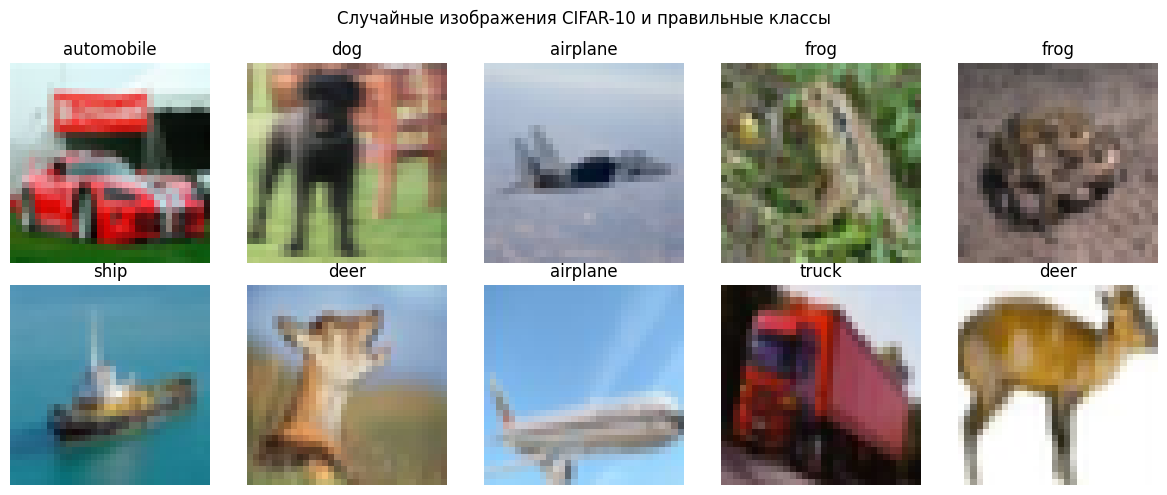

In [4]:
def denormalize(image):
    mean = torch.tensor(MEAN, dtype=image.dtype).view(3, 1, 1)
    std = torch.tensor(STD, dtype=image.dtype).view(3, 1, 1)
    return (image.cpu() * std + mean).clamp(0, 1)

rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(val_dataset), size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, example_indices):
    image, label = val_dataset[int(idx)]
    ax.imshow(denormalize(image).permute(1, 2, 0).numpy())
    ax.set_title(class_names[label])
    ax.axis("off")
plt.suptitle("Случайные изображения CIFAR-10 и правильные классы")
plt.tight_layout()
plt.show()

## 4. Гиперпараметры и загрузчики данных

При наличии GPU рекомендуется 35 эпох. Размер батча 128 — компромисс между использованием памяти и скоростью обучения. При необходимости время эксперимента можно сократить, уменьшив `EPOCHS`, но качество итоговой модели может снизиться.

In [14]:
BATCH_SIZE = 128
EPOCHS = 35
MAX_LR = 0.002
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2 if os.name != "nt" else 0
PIN_MEMORY = DEVICE.type == "cuda"
loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
}
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE * 2, shuffle=False, **loader_kwargs
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE * 2, shuffle=False, **loader_kwargs
)

xb, yb = next(iter(train_loader))
print("Размер одного батча изображений:", tuple(xb.shape))
print("Размер одного батча меток:", tuple(yb.shape))
print("Параметры:", {
    "batch_size": BATCH_SIZE, "epochs": EPOCHS,
    "max_learning_rate": MAX_LR, "weight_decay": WEIGHT_DECAY,
})

Размер одного батча изображений: (128, 3, 32, 32)
Размер одного батча меток: (128,)
Параметры: {'batch_size': 128, 'epochs': 35, 'max_learning_rate': 0.002, 'weight_decay': 0.0001}


## 5. Собственная архитектура CNN

In [15]:
def conv_block(in_channels, out_channels, pool=False):
    layers = [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    ]
    if pool:
        layers.append(nn.MaxPool2d(kernel_size=2))
    return nn.Sequential(*layers)


class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(x + self.layers(x))


class CustomCIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = conv_block(3, 64)
        self.down1 = conv_block(64, 128, pool=True)
        self.res1 = ResidualBlock(128)
        self.down2 = conv_block(128, 256, pool=True)
        self.down3 = conv_block(256, 512, pool=True)
        self.res2 = ResidualBlock(512)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.2),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.down1(x)
        x = self.res1(x)
        x = self.down2(x)
        x = self.down3(x)
        x = self.res2(x)
        return self.head(x)


model = CustomCIFAR10CNN(num_classes=len(class_names)).to(DEVICE)
param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Обучаемых параметров: {param_count:,}".replace(",", " "))
with torch.no_grad():
    test_logits = model(torch.zeros(2, 3, 32, 32, device=DEVICE))
print("Размер выхода сети:", tuple(test_logits.shape))
assert test_logits.shape == (2, 10)

CustomCIFAR10CNN(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (down1): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (res1): ResidualBlock(
    (layers): Sequential(
      (0): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_s

## 6. Функция потерь, оптимизатор и расписание скорости обучения

- **CrossEntropyLoss** — стандартная функция потерь для многоклассовой классификации.
- **AdamW** — адаптивный оптимизатор с регуляризацией весов (`weight_decay`).
- **OneCycleLR** — изменяет скорость обучения в течение эксперимента; обновляется после каждого батча.
- **Accuracy** — доля правильно классифицированных изображений.
- **Ошибка классификации** — доля ошибочных прогнозов: \(\mathrm{Error} = (1-\mathrm{Accuracy})\times100\%\).

В процессе обучения будут выведены **и средняя функция потерь, и ошибка классификации**, чтобы избежать неоднозначности термина «ошибка».

In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=MAX_LR,
    epochs=EPOCHS,
    steps_per_epoch=len(train_loader),
    pct_start=0.15,
)

# Mixed precision используется только на CUDA, ускоряя обучение на подходящих GPU.
USE_AMP = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
print("Функция потерь:", criterion.__class__.__name__)
print("Оптимизатор:", optimizer.__class__.__name__)
print("Планировщик:", scheduler.__class__.__name__)
print("Mixed precision:", USE_AMP)

Функция потерь: CrossEntropyLoss
Оптимизатор: AdamW
Планировщик: OneCycleLR
Mixed precision: False


## 7. Цикл обучения и валидации

После **каждой эпохи** выводятся loss, accuracy и classification error для обучающей и валидационной выборок. Метрики обучения считаются непосредственно на данных, прошедших аугментацию.

Сохраняем вариант с **максимальной точностью на валидации**. Только затем один раз проводим итоговое тестирование.

In [17]:
@torch.no_grad()
def evaluate(model, data_loader, criterion):
    model.eval()
    total_loss, total_correct, total_count = 0.0, 0, 0

    for images, targets in data_loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        targets = targets.to(DEVICE, non_blocking=PIN_MEMORY)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, targets)

        n = targets.size(0)
        total_loss += loss.item() * n
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_count += n

    avg_loss = total_loss / total_count
    accuracy = total_correct / total_count
    error = 1.0 - accuracy
    return {"loss": avg_loss, "accuracy": accuracy, "error": error}


def train_one_epoch(model, data_loader, criterion, optimizer, scheduler, scaler):
    model.train()
    total_loss, total_correct, total_count = 0.0, 0, 0

    for images, targets in tqdm(data_loader, desc="Обучение", leave=False):
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        targets = targets.to(DEVICE, non_blocking=PIN_MEMORY)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        n = targets.size(0)
        total_loss += loss.detach().item() * n
        total_correct += (logits.detach().argmax(dim=1) == targets).sum().item()
        total_count += n

    avg_loss = total_loss / total_count
    accuracy = total_correct / total_count
    error = 1.0 - accuracy
    return {"loss": avg_loss, "accuracy": accuracy, "error": error}

In [18]:
history = {"train_loss": [], "train_accuracy": [], "train_error": [],
           "val_loss": [], "val_accuracy": [], "val_error": []}
best_val_accuracy = -1.0
best_epoch = None
CHECKPOINT_PATH = Path("best_custom_cifar10_cnn.pth")

for epoch in range(1, EPOCHS + 1):
    print(f"\nЭпоха {epoch}/{EPOCHS}")
    train_metrics = train_one_epoch(
        model, train_loader, criterion, optimizer, scheduler, scaler
    )
    val_metrics = evaluate(model, val_loader, criterion)

    for metric in ("loss", "accuracy", "error"):
        history[f"train_{metric}"].append(train_metrics[metric])
        history[f"val_{metric}"].append(val_metrics[metric])

    if val_metrics["accuracy"] > best_val_accuracy:
        best_val_accuracy = val_metrics["accuracy"]
        best_epoch = epoch
        torch.save(model.state_dict(), CHECKPOINT_PATH)

    print(
        f"Train: loss={train_metrics['loss']:.4f}, "
        f"accuracy={train_metrics['accuracy']:.2%}, "
        f"ошибка={train_metrics['error']:.2%} | "
        f"Val: loss={val_metrics['loss']:.4f}, "
        f"accuracy={val_metrics['accuracy']:.2%}, "
        f"ошибка={val_metrics['error']:.2%}"
    )

print(f"\nЛучшая эпоха: {best_epoch}; точность на валидации: {best_val_accuracy:.2%}")
print("Веса модели сохранены:", CHECKPOINT_PATH.resolve())


Эпоха 1/35


Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Train: loss=1.3525, accuracy=50.42%, ошибка=49.58% | Val: loss=1.3760, accuracy=52.80%, ошибка=47.20%

Эпоха 2/35


Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Train: loss=0.9549, accuracy=66.07%, ошибка=33.93% | Val: loss=1.0346, accuracy=66.26%, ошибка=33.74%

Эпоха 3/35


Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

... (61 outputs left out)

Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Train: loss=0.0080, accuracy=99.76%, ошибка=0.24% | Val: loss=0.3136, accuracy=93.46%, ошибка=6.54%

Эпоха 35/35


Обучение:   0%|          | 0/352 [00:00<?, ?it/s]

Train: loss=0.0071, accuracy=99.83%, ошибка=0.17% | Val: loss=0.3126, accuracy=93.70%, ошибка=6.30%

Лучшая эпоха: 35; точность на валидации: 93.70%
Веса модели сохранены: C:\Users\kylae\Desktop\deep-learning-course-practice-2026\laboratory_work_2\best_custom_cifar10_cnn.pth


## 8. Графики процесса обучения

Левый график отображает изменение средней **CrossEntropyLoss**, правый — изменение **доли ошибок классификации**. Сравнение обучения и валидации помогает выявить переобучение.

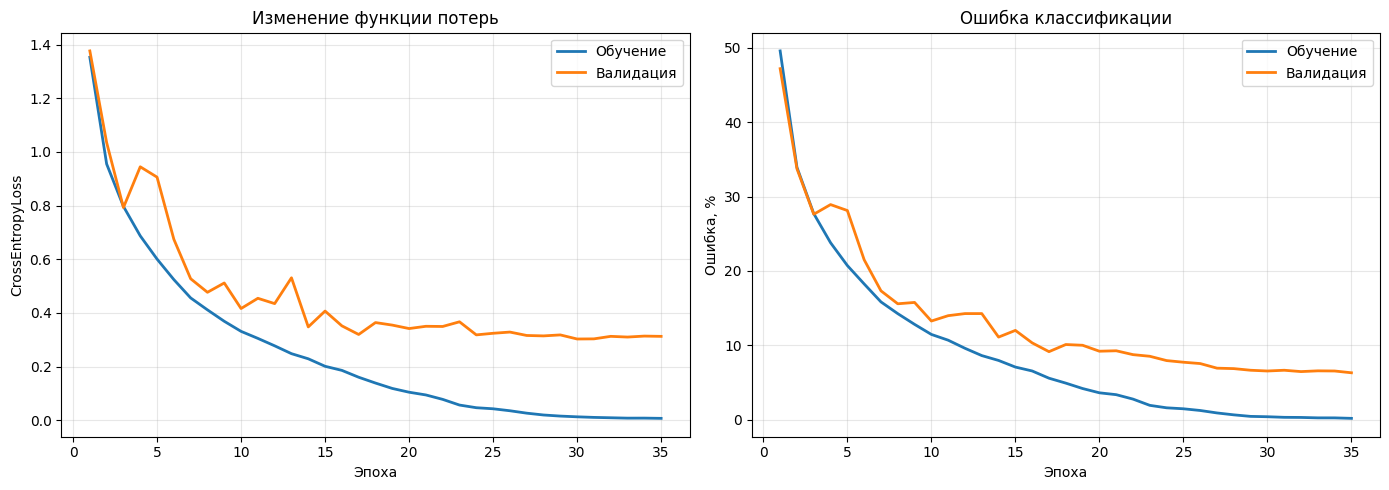

In [19]:
assert len(history["train_loss"]) == EPOCHS, "Сначала выполните обучение модели."
epochs_axis = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(epochs_axis, history["train_loss"], label="Обучение", linewidth=2)
axes[0].plot(epochs_axis, history["val_loss"], label="Валидация", linewidth=2)
axes[0].set(title="Изменение функции потерь", xlabel="Эпоха", ylabel="CrossEntropyLoss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_axis, np.array(history["train_error"]) * 100,
             label="Обучение", linewidth=2)
axes[1].plot(epochs_axis, np.array(history["val_error"]) * 100,
             label="Валидация", linewidth=2)
axes[1].set(title="Ошибка классификации", xlabel="Эпоха", ylabel="Ошибка, %")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Итоговая оценка на независимой тестовой выборке

Восстанавливаем сохранённые веса лучшей модели. Тестовый набор используется только **после** выбора архитектуры и гиперпараметров.

In [20]:
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))
test_metrics = evaluate(model, test_loader, criterion)

print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ")
print(f"  Количество изображений: {len(test_dataset)}")
print(f"  Средняя функция потерь: {test_metrics['loss']:.4f}")
print(f"  Точность (Accuracy):    {test_metrics['accuracy']:.2%}")
print(f"  Ошибка классификации:  {test_metrics['error']:.2%}")
print(f"  Лучшая эпоха:          {best_epoch}")
assert abs(test_metrics["accuracy"] + test_metrics["error"] - 1) < 1e-9

ИТОГОВЫЕ РЕЗУЛЬТАТЫ НА ТЕСТОВОЙ ВЫБОРКЕ
  Количество изображений: 10000
  Средняя функция потерь: 0.3550
  Точность (Accuracy):    92.88%
  Ошибка классификации:  7.12%
  Лучшая эпоха:          35


## 10. Дополнительная оценка: матрица ошибок и точность по классам

Матрица ошибок показывает, какие пары классов сеть чаще всего путает. Это помогает интерпретировать качество модели не только по общей accuracy.

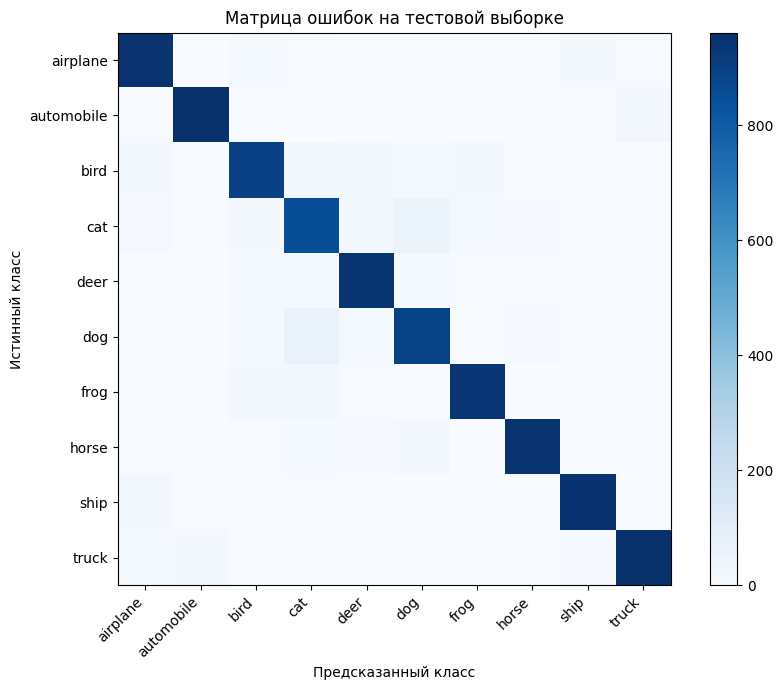

Точность по классам:
  airplane    : 94.60%
  automobile  : 96.10%
  bird        : 90.00%
  cat         : 85.20%
  deer        : 94.40%
  dog         : 89.00%
  frog        : 93.80%
  horse       : 94.80%
  ship        : 95.30%
  truck       : 95.60%


In [21]:
confusion = torch.zeros(10, 10, dtype=torch.long)
model.eval()
with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        pred = model(images).argmax(dim=1).cpu()
        targets = targets.cpu()
        confusion += torch.bincount(targets * 10 + pred, minlength=100).reshape(10, 10)

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(confusion.numpy(), cmap="Blues")
ax.set_xticks(range(10), class_names, rotation=45, ha="right")
ax.set_yticks(range(10), class_names)
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
ax.set_title("Матрица ошибок на тестовой выборке")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

class_accuracy = confusion.diag().float() / confusion.sum(dim=1).clamp(min=1)
print("Точность по классам:")
for name, acc in zip(class_names, class_accuracy):
    print(f"  {name:12s}: {acc.item():.2%}")

## 11. Автоматически сформированный вывод по результатам

После обучения следующая ячейка напечатает фактические значения из эксперимента. В отчёт следует переносить только реальные полученные метрики.

In [22]:
train_end = history["train_accuracy"][-1]
val_end = history["val_accuracy"][-1]
overfit_gap = train_end - val_end

print("ВЫВОД")
print(
    "В ходе лабораторной работы была реализована собственная сверточная "
    "нейронная сеть на PyTorch с остаточными блоками для классификации CIFAR-10."
)
print(
    f"Обучение продолжалось {EPOCHS} эпох; лучшая эпоха по валидации — {best_epoch} "
    f"(accuracy {best_val_accuracy:.2%})."
)
print(
    f"По итогам тестирования на {len(test_dataset)} независимых изображениях "
    f"точность составила {test_metrics['accuracy']:.2%}, "
    f"ошибка классификации — {test_metrics['error']:.2%}, "
    f"CrossEntropyLoss — {test_metrics['loss']:.4f}."
)
print(
    f"К концу обучения accuracy на тренировочной выборке составила "
    f"{train_end:.2%}, на валидационной — {val_end:.2%}. "
    f"Разница составляет {overfit_gap * 100:.2f} п.п. "
    "(метрика обучения вычислена с аугментациями)."
)
print(
    "Задачи лабораторной работы выполнены: данные загружены и обработаны, "
    "сеть реализована из базовых слоёв PyTorch, гиперпараметры заданы, "
    "обучение и независимая проверка качества проведены."
)

ВЫВОД
В ходе лабораторной работы была реализована собственная сверточная нейронная сеть на PyTorch с остаточными блоками для классификации CIFAR-10.
Обучение продолжалось 35 эпох; лучшая эпоха по валидации — 35 (accuracy 93.70%).
По итогам тестирования на 10000 независимых изображениях точность составила 92.88%, ошибка классификации — 7.12%, CrossEntropyLoss — 0.3550.
К концу обучения accuracy на тренировочной выборке составила 99.83%, на валидационной — 93.70%. Разница составляет 6.13 п.п. (метрика обучения вычислена с аугментациями).
Задачи лабораторной работы выполнены: данные загружены и обработаны, сеть реализована из базовых слоёв PyTorch, гиперпараметры заданы, обучение и независимая проверка качества проведены.
